In [1]:
import joblib
import pandas as pd

# 1. Load the saved model back from your disk
loaded_model = joblib.load('/content/drive/MyDrive/ML projects/iot_intrusion.pkl')
print("Loaded balanced model successfully!")
scaler = joblib.load('/content/drive/MyDrive/ML projects/scaler.pkl')

# 2. Automatically grab the exact feature names the model was trained on
feature_names = loaded_model.feature_names_in_

# 3. Create a test packet using those stored names
sample_packet = pd.DataFrame([[1] * len(feature_names)], columns=feature_names)

# 4. Predict cleanly without warnings
prediction = loaded_model.predict(sample_packet)
print(f"Prediction for incoming packet: {prediction[0]}")

Loaded balanced model successfully!
Prediction for incoming packet: DDoS-ICMP_Flood


In [2]:
print(loaded_model.get_params())

{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 30, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


In [3]:
import pandas as pd

print("Loading and preparing dataset (this happens only once)...")

df = pd.read_csv('/content/drive/MyDrive/ML projects/train.csv')
df_encoded = pd.get_dummies(df)

X_features = df_encoded.drop(columns=[c for c in df_encoded.columns if 'label' in c])
X_features = X_features.reindex(columns=loaded_model.feature_names_in_, fill_value=0)
print("Ready! Dataset is cached in memory.")

Loading and preparing dataset (this happens only once)...
Ready! Dataset is cached in memory.


In [4]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report

# 1. Load your validation dataset
val_df = pd.read_csv('/content/drive/MyDrive/ML projects/validation.csv')

# 2. Encode and align features to match the model's expected features
val_encoded = pd.get_dummies(val_df)
X_val = val_encoded.drop(columns=[c for c in val_encoded.columns if 'label' in c])
X_val = X_val.reindex(columns=loaded_model.feature_names_in_, fill_value=0)
y_val = val_df['label']

# 3. Scale the validation features using the same fitted scaler
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=loaded_model.feature_names_in_)

# 4. Predict and evaluate using the scaled data
val_preds = loaded_model.predict(X_val_scaled)
val_acc = accuracy_score(y_val, val_preds)

print(f"Validation Accuracy: {val_acc * 100:.2f}%\n")
print("Validation Classification Report:")
print(classification_report(y_val, val_preds, zero_division=0))

Validation Accuracy: 97.95%

Validation Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.02      0.02      0.02        93
          BenignTraffic       0.82      0.84      0.83     27519
       BrowserHijacking       0.00      0.00      0.00       158
       CommandInjection       0.00      0.00      0.00       132
 DDoS-ACK_Fragmentation       0.97      0.96      0.97      7194
        DDoS-HTTP_Flood       0.75      0.71      0.73       706
        DDoS-ICMP_Flood       1.00      1.00      1.00    182011
DDoS-ICMP_Fragmentation       1.00      0.98      0.99     11430
      DDoS-PSHACK_Flood       0.99      1.00      1.00    102985
       DDoS-RSTFINFlood       1.00      1.00      1.00    101563
         DDoS-SYN_Flood       0.99      0.99      0.99    102644
         DDoS-SlowLoris       0.31      0.15      0.20       620
DDoS-SynonymousIP_Flood       1.00      0.99      0.99     90795
         DDoS-TCP_Flood   

In [5]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report

# 1. Load your testing dataset
test_df = pd.read_csv('/content/drive/MyDrive/ML projects/test.csv')

# 2. Encode and align features to match the model's expected features
test_encoded = pd.get_dummies(test_df)
X_test = test_encoded.drop(columns=[c for c in test_encoded.columns if 'label' in c])
X_test = X_test.reindex(columns=loaded_model.feature_names_in_, fill_value=0)
y_test = test_df['label']

# 3. Scale the testing features using the same fitted scaler
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=loaded_model.feature_names_in_)

# 4. Predict and evaluate using the scaled data
test_preds = loaded_model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, test_preds)

print(f"Testing Accuracy: {test_acc * 100:.2f}%\n")
print("Testing Classification Report:")
print(classification_report(y_test, test_preds, zero_division=0))

Testing Accuracy: 97.94%

Testing Classification Report:
                         precision    recall  f1-score   support

       Backdoor_Malware       0.00      0.00      0.00        89
          BenignTraffic       0.82      0.84      0.83     27709
       BrowserHijacking       0.00      0.00      0.00       134
       CommandInjection       0.00      0.00      0.00       119
 DDoS-ACK_Fragmentation       0.97      0.96      0.97      7292
        DDoS-HTTP_Flood       0.76      0.72      0.74       709
        DDoS-ICMP_Flood       1.00      1.00      1.00    180447
DDoS-ICMP_Fragmentation       1.00      0.98      0.99     11402
      DDoS-PSHACK_Flood       0.99      1.00      1.00    103326
       DDoS-RSTFINFlood       1.00      1.00      1.00    101819
         DDoS-SYN_Flood       0.99      0.99      0.99    102208
         DDoS-SlowLoris       0.34      0.16      0.22       622
DDoS-SynonymousIP_Flood       1.00      0.99      0.99     90480
         DDoS-TCP_Flood       0.

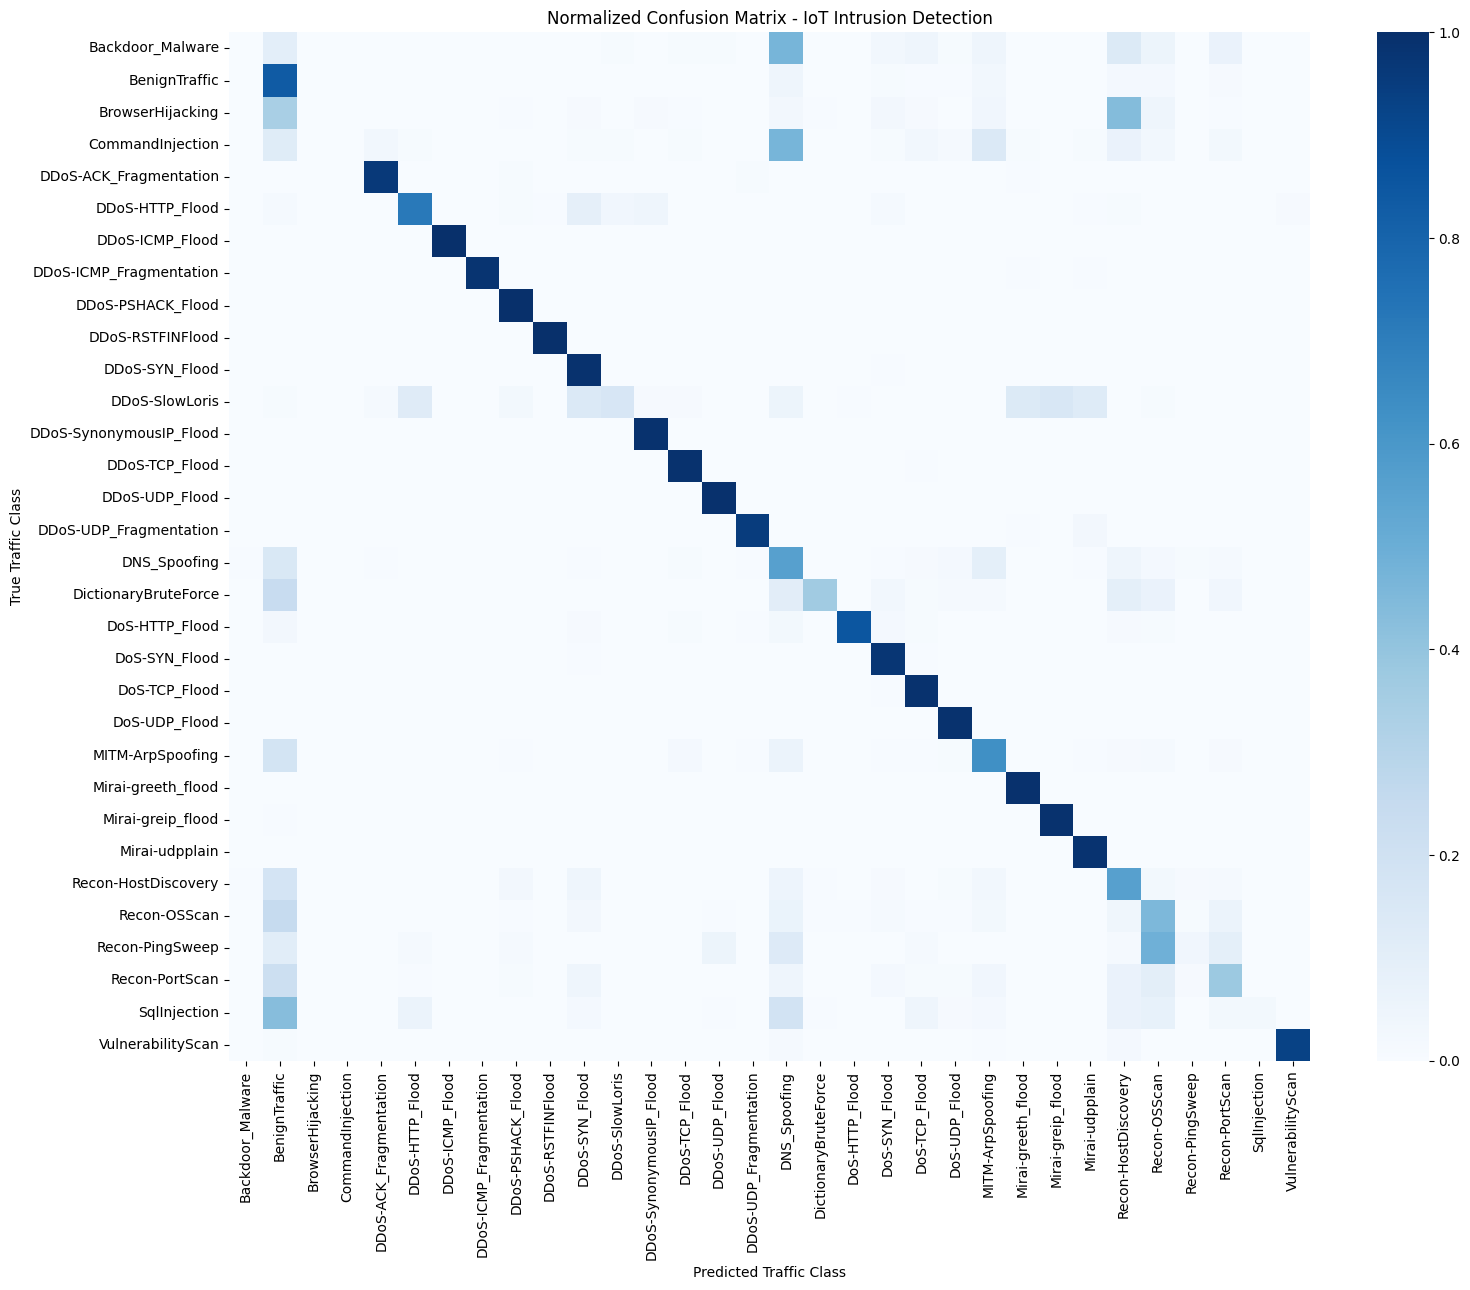

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_preds, labels=loaded_model.classes_)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(16, 13))
sns.heatmap(cm_norm, annot=False, cmap='Blues', vmin=0, vmax=1,
            xticklabels=loaded_model.classes_,
            yticklabels=loaded_model.classes_)
plt.title('Normalized Confusion Matrix - IoT Intrusion Detection')
plt.xlabel('Predicted Traffic Class')
plt.ylabel('True Traffic Class')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()
from google.colab import files
files.download('confusion_matrix.png')

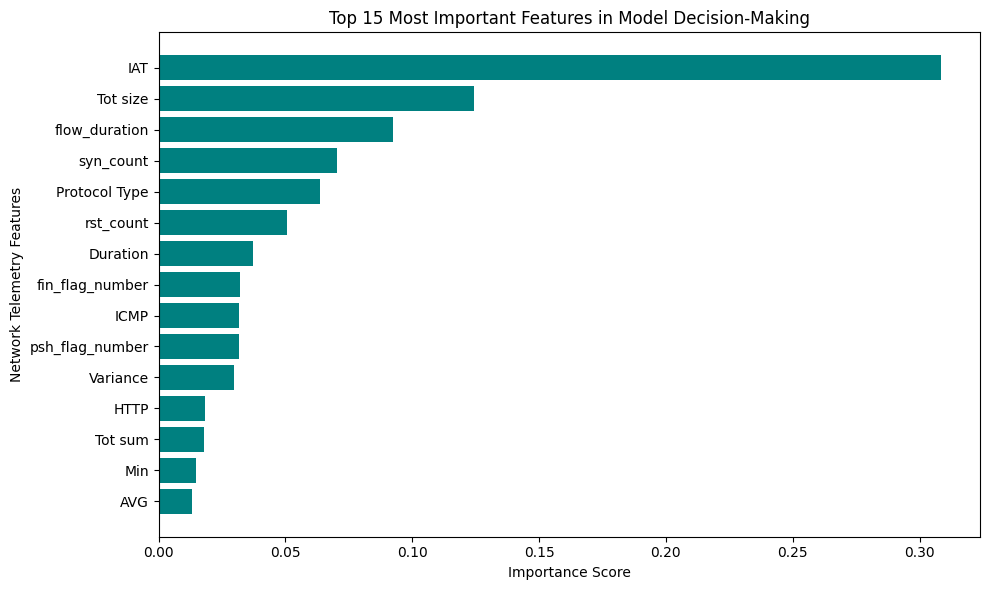

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files # <--- Added for Colab download

# Extract feature importances from the decision tree
importances = loaded_model.feature_importances_
feature_names = loaded_model.feature_names_in_

# Create a dataframe and select top 15 features
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(15)

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.ylabel('Network Telemetry Features')
plt.title('Top 15 Most Important Features in Model Decision-Making')
plt.gca().invert_yaxis()
plt.tight_layout()

# --- Added lines to save and download ---
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
files.download('feature_importance.png')

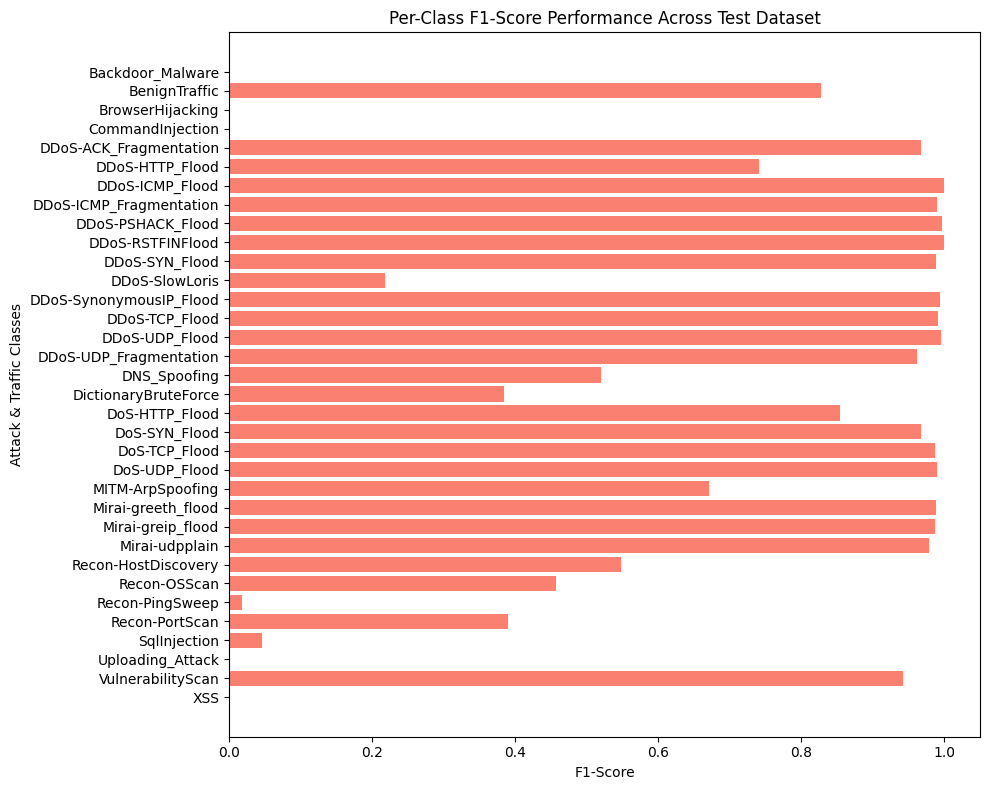

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import pandas as pd
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from google.colab import files # <--- Added for Colab download

# Extract classification report dictionary
report_dict = classification_report(y_test, test_preds, output_dict=True, zero_division=0)
metrics_df = pd.DataFrame(report_dict).T
metrics_df = metrics_df.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Plot F1-scores per class
plt.figure(figsize=(10, 8))
plt.barh(metrics_df.index, metrics_df['f1-score'], color='salmon')
plt.xlabel('F1-Score')
plt.ylabel('Attack & Traffic Classes')
plt.title('Per-Class F1-Score Performance Across Test Dataset')
plt.xlim(0, 1.05)
plt.gca().invert_yaxis()
plt.tight_layout()

# --- Added lines to save and download ---
plt.savefig('per_class_f1_scores.png', dpi=300, bbox_inches='tight')
plt.show()
files.download('per_class_f1_scores.png')